In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Настройка визуального оформления графиков
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 13
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.autolayout'] = True

# Фиксируем random seed для детерминированности
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
def make_airbnb_dirty(df):
    data = df.copy()
    base_price = data["price"].astype(int).astype(str)
    idx = np.arange(len(data))

    data["price"] = base_price
    data.loc[idx % 3 == 0, "price"] = "$" + base_price[idx % 3 == 0]
    data.loc[idx % 5 == 0, "price"] = base_price[idx % 5 == 0].map(
        lambda x: f"{int(x):,} USD"
    )
    data.loc[idx % 7 == 0, "price"] = "  " + base_price[idx % 7 == 0] + "  "
    data.loc[idx % 11 == 0, "price"] = base_price[idx % 11 == 0] + ".00 Rub"

    data["name"] = data["name"].fillna("")
    data.loc[idx % 6 == 0, "name"] = data.loc[idx % 6 == 0, "name"].str.upper() + "!!!"
    data.loc[idx % 10 == 0, "name"] = "🔥 " + data.loc[idx % 10 == 0, "name"]
    return data

def plot_distribution(series, ax=None, title_prefix="Распределение", color="royalblue"):
    """
    Универсальная функция: строит histplot с кривой KDE.
    Если ax=None, создает отдельное окно. Если ax передан, встраивается в сетку.
    """
    data = series.dropna()
    mean_val = data.mean()
    median_val = data.median()
    std_val = data.std()
    n = len(data)
    skew_val = data.skew()
    se_mean = std_val / np.sqrt(n)
    diff_ratio = abs(mean_val - median_val) / se_mean if se_mean > 0 else 0

    # ФЛАГ: запоминаем, создали ли мы ось сами
    own_ax = False
    if ax is None:
        fig, ax = plt.subplots(figsize=(8.5, 4.5))
        own_ax = True # помечаем, что график одиночный

    # Отрисовка на оси ax
    sns.histplot(data, kde=True, color=color, bins=40, ax=ax, edgecolor="black", alpha=0.55)

    ax.axvline(mean_val, color="crimson", linestyle="--", linewidth=2, label=f"Среднее: {mean_val:.1f}")
    ax.axvline(median_val, color="darkgreen", linestyle="-", linewidth=2, label=f"Медиана: {median_val:.1f}")

    info_text = (f"Skewness: {skew_val:.2f}\n"
                f"Показатель (|x̄ - Me| / SE): {diff_ratio:.2f}\n")
    ax.text(
        0.97, 0.70, info_text, transform=ax.transAxes, fontsize=10,
        verticalalignment="top", horizontalalignment="right",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="gray", alpha=0.85)
    )

    col_name = series.name if series.name else "Признак"
    ax.set_title(f"{title_prefix}: {col_name}")
    ax.set_xlabel(col_name)
    ax.set_ylabel("Частота")
    ax.legend(loc="upper right")

    # Если ось была создана внутри функции, сами красиво закрываем график
    if own_ax:
        plt.tight_layout()
        plt.show()
        
def plot_boxplot_bounds(series, title="Анализ выбросов"):
    """
    Строит boxplot с нанесением границ IQR, квантилей и медианы.
    """
    data = series.dropna()
    q25 = data.quantile(0.25)
    median = data.median()
    mean = np.mean(data)
    q75 = data.quantile(0.75)
    iqr = q75 - q25
    
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.boxplot(x=data, ax=ax, color='lightsteelblue', flierprops={"marker": "o", "markerfacecolor": "crimson", "alpha": 0.5})
    
    ax.axvline(q25, color='blue', linestyle=':', label=f'Q25: {q25:.1f}')
    ax.axvline(mean, color="crimson", linestyle="--", linewidth=2, label=f"Среднее: {mean:.1f}")
    ax.axvline(median, color="darkgreen", linestyle="-", linewidth=2, label=f"Медиана: {median:.1f}")
    ax.axvline(q75, color='blue', linestyle=':', label=f'Q75: {q75:.1f}')
    
    outliers_count = (data > q75 + 1.5 * iqr).sum() + (data < (q25 - 1.5 * iqr)).sum()
    ax.set_title(f"{title}: {series.name} (Выбросов: {outliers_count} из {len(data)})")
    ax.legend(loc='upper right')
    plt.show()
    
def remove_outliers_quartiles(df, column, factor=1.5):
    """
    Фильтрует строки датафрейма по межквартильным границам Тьюки.
    """
    q25 = df[column].quantile(0.25)
    q75 = df[column].quantile(0.75)
    iqr = q75 - q25
    lower_bound = q25 - factor * iqr
    upper_bound = q75 + factor * iqr
    
    filtered_df = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)].copy()
    dropped_count = len(df) - len(filtered_df)
    print(f"Признак '{column}': удалено {dropped_count} записей ({dropped_count/len(df)*100:.1f}%). Осталось: от {lower_bound} до {upper_bound}")
    return filtered_df

def remove_outliers_sigma(df, column, factor=3):
    """
    Фильтрует строки датафрейма по правилу трех сигм (или заданному числу factor).
    """
    mean_val = df[column].mean()
    std_val = df[column].std()
    
    lower_bound = mean_val - factor * std_val
    upper_bound = mean_val + factor * std_val
    
    filtered_df = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)].copy()
    
    dropped_count = len(df) - len(filtered_df)
    print(f"Признак '{column}': удалено {dropped_count} записей ({dropped_count/len(df)*100:.1f}%). Осталось: от {lower_bound:.2f} до {upper_bound:.2f}")
    
    return filtered_df

def train_test_linear_regression(dataframe, feature_columns, target):

    X = dataframe[feature_columns]
    y = dataframe[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=RANDOM_STATE
    )

    # 5. Обучаем модель и оцениваем качество
    model = LinearRegression()

    try:
        model.fit(X_train, y_train)
        
        test_pred = model.predict(X=X_test)
        train_pred = model.predict(X=X_train)
        
        train_r2 = r2_score(y_true=y_train, y_pred=train_pred)
        test_r2 = r2_score(y_true=y_test, y_pred=test_pred)

        print(f"--- Результаты ---")
        print(f"R² на обучающей выборке (train): {train_r2:.3f}")
        print(f"R² на тесте (test): {test_r2:.4f}")
        return model
    except ValueError as e:
        print("=" * 80)
        print("КРИТИЧЕСКАЯ ОШИБКА ОБУЧЕНИЯ (Traceback):")
        print(e)
        print("=" * 80)

## 1. Введение и концепция EDA (Exploratory Data Analysis)

In [3]:
# Загружаем датасет Airbnb и берём 45000 образцов 
df_global = pd.read_csv('data/AB_NYC_2019.csv')
df_global = df_global.sample(n=45000, random_state=RANDOM_STATE)

# Переименование колонок в понятные русскоязычные термины
df_global = df_global.rename(columns={
    'id': 'listing_id',                         # Уникальный номер объявления
    'name': 'name',                            # Название объявления
    'host_id': 'host_id',                       # Идентификатор хозяина
    'host_name': 'host_name',                   # Имя хозяина
    'neighbourhood_group': 'borough',           # Административный округ (Манхэттен, Бруклин и т.д.)
    'neighbourhood': 'neighborhood',            # Микрорайон
    'latitude': 'latitude',                     # Географическая широта
    'longitude': 'longitude',                   # Географическая долгота
    'room_type': 'room_type',                   # Тип сдаваемого жилья (Entire apt, Private room, Shared)
    'price': 'price',                           # ТАРГЕТ: Цена аренды за сутки ($)
    'minimum_nights': 'min_nights',             # Минимальное число ночей
    'number_of_reviews': 'reviews_count',       # Общее число отзывов
    'last_review': 'last_review_date',          # Дата последнего отзыва
    'reviews_per_month': 'reviews_per_month',   # Среднее число отзывов в месяц
    'calculated_host_listings_count': 'host_listings_count', # Количество объектов у данного хоста
    'availability_365': 'availability_365'      # Доступность объекта в году (в днях)
})

# Загрязняем и выводим
df_global = make_airbnb_dirty(df_global)
df_global.sample(8, random_state=42)

,listing_id,name,host_id,host_name,borough,neighborhood,latitude,longitude,room_type,price,min_nights,reviews_count,last_review_date,reviews_per_month,host_listings_count,availability_365
5392,3896701,Spacious Master Bed w Private Ensuite Bath in EV,20172814,Jesse,Manhattan,East Village,40.72859,-73.97915,Private room,129,4,32,2019-05-25,0.56,1,365
32741,25802560,Bright Big Beautiful Apt border Bushwick/Ridge...,3543204,Andrea,Brooklyn,Bushwick,40.70400,-73.91492,Private room,75.00 Rub,2,19,2019-06-03,1.47,1,198
33576,26566291,"QUIET, PRIVATE AND SUNNY IN GREENWICH VILLAGE!!!",186452920,Rose,Manhattan,Greenwich Village,40.73093,-74.00125,Entire home/apt,200,2,42,2019-06-21,3.62,1,129
46225,35158573,Modern peaceful room in lively East Williamsburg,59188298,John,Brooklyn,Williamsburg,40.71118,-73.94561,Private room,75,2,0,NaN,NaN,1,144
34540,27389854,🔥 Queens Apartment,206400943,Homemattie,Queens,Richmond Hill,40.69103,-73.83407,Entire home/apt,150 USD,3,6,2019-06-25,0.55,1,162
14428,11319227,A HOME AWAY FROM HOME IN NYC! UPTOWN,51025844,Kdn,Manhattan,Inwood,40.86761,-73.92718,Shared room,29 USD,1,93,2019-06-15,2.28,3,90
42969,33367026,Artist apartment in the heart of Brooklyn!,27445710,Nikolay,Brooklyn,Flatbush,40.64582,-73.96479,Entire home/apt,80 USD,1,1,2019-03-29,0.29,1,0
43591,33743082,"NEWLY-RENOVATED APARTMENT, 35 MINS FROM MANHATTAN",619942,Stacy & Simon,Brooklyn,Cypress Hills,40.68935,-73.87254,Entire home/apt,150,30,0,NaN,NaN,6,17


### Падение классической линейной регрессии без обработки данных

$R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2}$


In [4]:
# Выбираем числовые признаки и таргет (строки не берём, от них модель сразу упадёт)
numeric_cols = ['latitude', 'longitude', 'min_nights', 'reviews_count', 
                'reviews_per_month', 'host_listings_count', 'availability_365']

model = train_test_linear_regression(df_global, numeric_cols, 'price')

КРИТИЧЕСКАЯ ОШИБКА ОБУЧЕНИЯ (Traceback):
Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values


---
## 2. Типология данных в машинном обучении
Правильное понимание природы признаков предопределяет стратегию предобработки, метрики расстояния и методы кодирования.

In [5]:
# Узнаём все типы данных
df_global.info()

<class 'pandas.core.frame.DataFrame'>
Index: 45000 entries, 879 to 27233
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   listing_id           45000 non-null  int64  
 1   name                 45000 non-null  object 
 2   host_id              45000 non-null  int64  
 3   host_name            44980 non-null  object 
 4   borough              45000 non-null  object 
 5   neighborhood         45000 non-null  object 
 6   latitude             45000 non-null  float64
 7   longitude            45000 non-null  float64
 8   room_type            45000 non-null  object 
 9   price                45000 non-null  object 
 10  min_nights           45000 non-null  int64  
 11  reviews_count        45000 non-null  int64  
 12  last_review_date     35737 non-null  object 
 13  reviews_per_month    35737 non-null  float64
 14  host_listings_count  45000 non-null  int64  
 15  availability_365     45000 non-null  in

In [6]:
print(df_global['listing_id'][0], df_global['listing_id'][1000])

2539 404923


In [7]:
# почистим датасет от ужасных значений price и строковых признаков. 
# ПОТЕРЯЛИ ДЕЛЕНИЕ НА RUB И USD!!!
df_global["price"] = (df_global["price"]
                    .astype(str)
                    .str.lower()
                    .str.replace('$', '')
                    .str.replace('usd', '')
                    .str.replace('rub', '')
                    .str.replace(',', '')
                    .str.strip()
                    .astype(float))

pattern_for_name = r"[^a-zа-я0-9\s\.\,\!\?\;\:\(\)\'\"\-\|]"
df_global["name"] = (df_global["name"]
                    .astype(str)
                    .str.lower()
                    .str.replace(pattern_for_name, '', regex=True)
                    .str.strip())

df_global[
    ["name", "room_type", "price", "min_nights", "reviews_per_month"]
].sample(8, random_state=42)

,name,room_type,price,min_nights,reviews_per_month
5392,spacious master bed w private ensuite bath in ev,Private room,129.0,4,0.56
32741,bright big beautiful apt border bushwickridgewood,Private room,75.0,2,1.47
33576,"quiet, private and sunny in greenwich village!!!",Entire home/apt,200.0,2,3.62
46225,modern peaceful room in lively east williamsburg,Private room,75.0,2,NaN
34540,queens apartment,Entire home/apt,150.0,3,0.55
14428,a home away from home in nyc! uptown,Shared room,29.0,1,2.28
42969,artist apartment in the heart of brooklyn!,Entire home/apt,80.0,1,0.29
43591,"newly-renovated apartment, 35 mins from manhattan",Entire home/apt,150.0,30,NaN


---
## 3. Первичный технический аудит датасета

Проверяем размерность матрицы, технические типы, фактические пропуски и физический смысл минимальных/максимальных значений.

In [8]:
print("Размерность выборки (N строк x D столбцов)")
print(f"Shape: {df_global.shape}")

Размерность выборки (N строк x D столбцов)
Shape: (45000, 16)


In [9]:
# Описательная статистика для числовых признаков, округлённая до 1 знака
df_global.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
listing_id,45000.0,19039193.3,10986393.8,2539.0,9488849.0,19713970.5,29179840.8,36487245.0
host_id,45000.0,67664852.1,78607765.2,2438.0,7831209.0,30930559.5,107434423.0,274321313.0
latitude,45000.0,40.7,0.1,40.5,40.7,40.7,40.8,40.9
longitude,45000.0,-74.0,0.0,-74.2,-74.0,-74.0,-73.9,-73.7
price,45000.0,152.2,230.7,0.0,69.0,105.0,175.0,10000.0
min_nights,45000.0,7.0,20.9,1.0,1.0,2.0,5.0,1250.0
reviews_count,45000.0,23.2,44.5,0.0,1.0,5.0,23.0,629.0
reviews_per_month,35737.0,1.4,1.7,0.0,0.2,0.7,2.0,58.5
host_listings_count,45000.0,7.2,33.0,1.0,1.0,1.0,2.0,327.0
availability_365,45000.0,112.7,131.6,0.0,0.0,45.0,226.0,365.0


---
## 4. Исследование распределений и визуализация

### Теоретический базис:
* Симметричное (нормальное) распределение характеризуется совпадением среднего и медианы: $\bar{x} \approx \text{Me}$.
### Экспресс-критерий симметрии:
$$\frac{\vert{}\bar{x} - \text{Me}\vert{}}{SE} \le 3$$
### Коэффициент асимметрии (Skewness) — мера скошенности распределения
**Как интерпретировать:**
* $\vert{}\text{Skew}\vert{} \le 0.5$ — распределение **симметрично** (нормальное).
* $0.5 < \vert{}\text{Skew}\vert{} \le 1.0$ — умеренный скос.
* $\vert{}\text{Skew}\vert{} > 1.0$ — **сильная асимметрия** (нужна трансформация `log1p`, иначе линейные модели исказят веса).


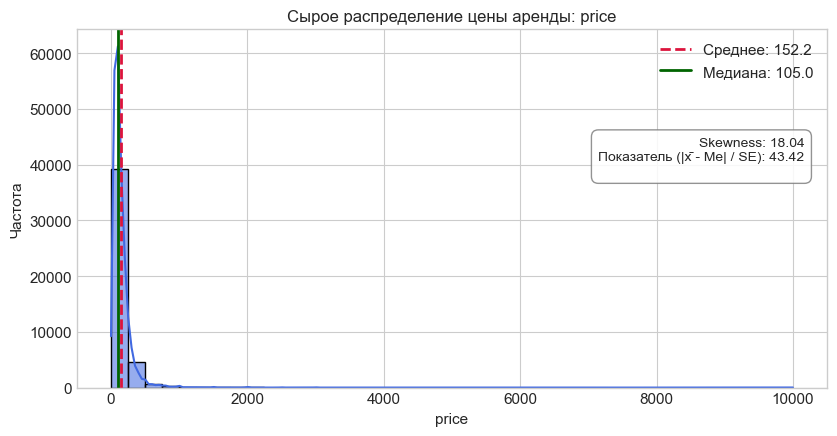

In [10]:
# 1. Распределение сырой цены (price)
plot_distribution(df_global["price"], title_prefix="Сырое распределение цены аренды")

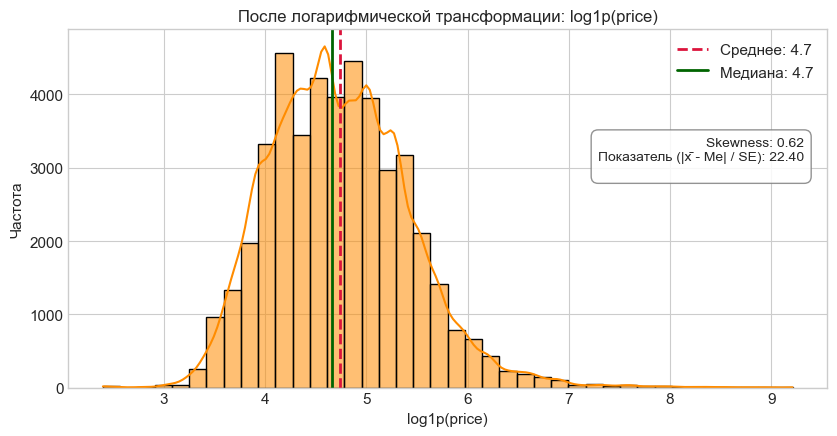

In [11]:
# Применяем log1p к целевой переменной
price_log = np.log1p(df_global[df_global['price'] > 0]['price'])
price_log.name = 'log1p(price)'

plot_distribution(price_log, title_prefix="После логарифмической трансформации", color="darkorange")

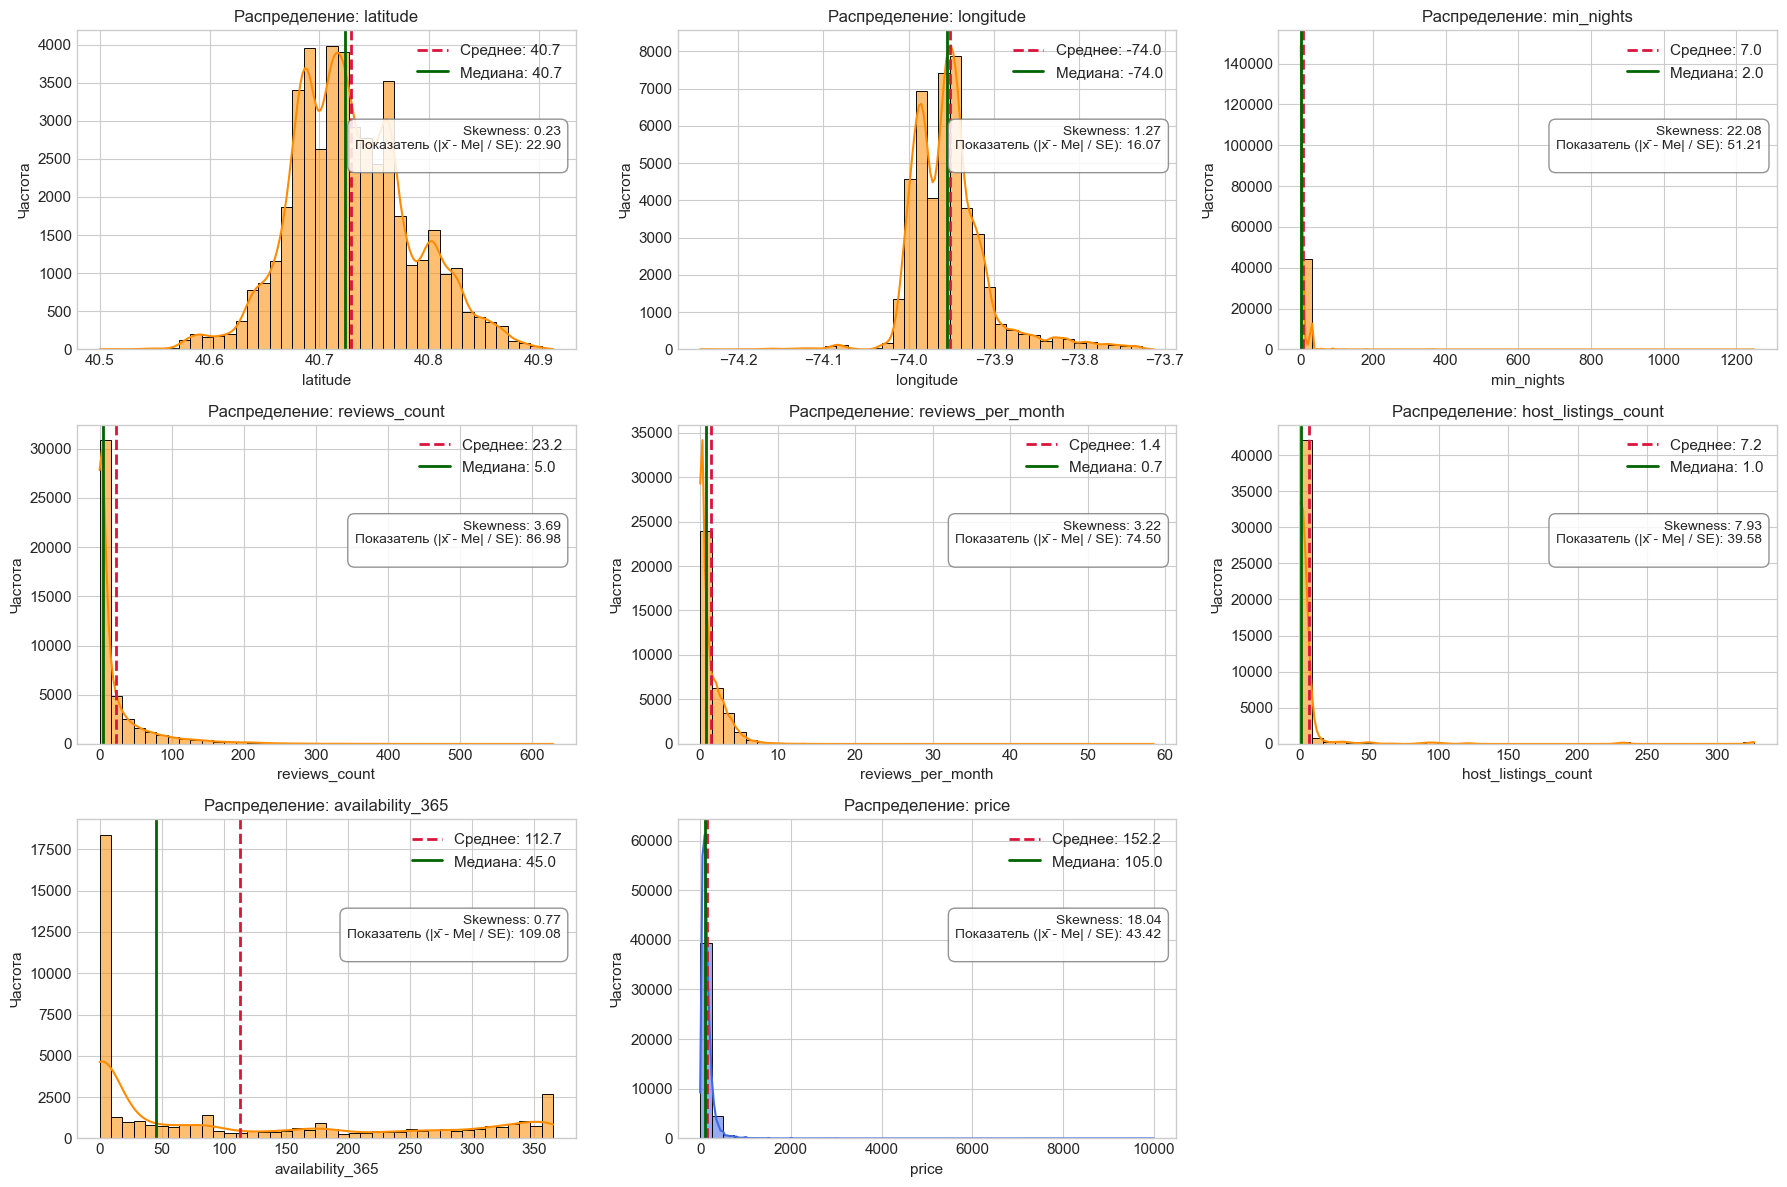

In [12]:
features_to_plot = numeric_cols + ["price"]
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 12))
axes_flat = axes.flatten()

for i, col in enumerate(features_to_plot):
    color = "royalblue" if col == "price" else "darkorange"
    plot_distribution(df_global[col], ax=axes_flat[i], color=color)

for j in range(len(features_to_plot), len(axes_flat)):
    axes_flat[j].set_visible(False)    

plt.tight_layout()
plt.show()

In [13]:
# можно не строить красивые графики с нейронкой, а просто написать самому. не очень красиво, зато быстро и кратко
# df_global[features_to_plot].hist(
#     bins=40, alpha=0.7, edgecolor="black", figsize=(18, 12)
# )
# plt.tight_layout() # чтобы не наезжали друг на друга названия
# plt.show()

---
## 5. Выбросы (Outliers): обнаружение и стратегии обработки


### Классификация выбросов:
1. **Ошибочные данные (Noise / Errors)**: нулевая стоимость суток аренды (`price == 0`) или `min_nights == 1250`. Подлежат удалению или клиппингу.
2. **Реальные экстремумы (Rare Patterns)**: пентхаус на Манхэттене за $5,000 в сутки — это не ошибка ввода, а отражение элитного сегмента рынка.

### Методы идентификации:
1. **Правило Тьюки (Межквартильный размах $IQR$)**:
   * $IQR = Q_{75} - Q_{25}$
   * Границы допустимого диапазона: $[Q_{25} - 1.5 \cdot IQR; \; Q_{75} + 1.5 \cdot IQR]$.
   * Точки за пределами усов считаются потенциальными выбросами.
2. **Правило $3\sigma$ и $5\sigma$**:
   * Для распределений, близких к нормальному (гауссову), 99.7% данных лежат в интервале $[\mu - 3\sigma, \; \mu + 3\sigma]$.
   * Для асимметричных распределений с тяжелыми хвостами порог сдвигают до $5\sigma$.

Левый ус=2.8655121125661713, правый ус=6.553467124521339


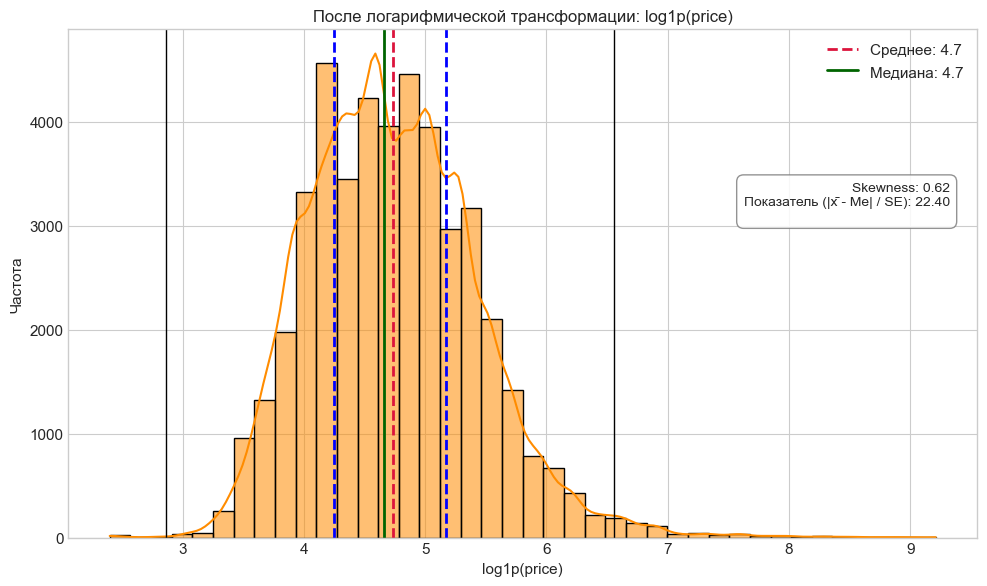

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
plot_distribution(
    price_log,
    ax=ax,
    title_prefix="После логарифмической трансформации",
    color="darkorange",
)
q25_price_log = price_log.quantile(0.25)
q75_price_log = price_log.quantile(0.75)
iqr = q75_price_log - q25_price_log
ax.axvline(
    q25_price_log,
    color="blue",
    linestyle="--",
    linewidth=2,
    label=f"0.25: {q25_price_log:.1f}",
)
ax.axvline(
    q75_price_log,
    color="blue",
    linestyle="--",
    linewidth=2,
    label=f"0.75: {q75_price_log:.1f}",
)
ax.axvline(
    q25_price_log - 1.5 * iqr,
    color="black",
    linewidth=1,
    label=f"0.25: {q25_price_log:.1f}",
)
ax.axvline(
    q75_price_log + 1.5 * iqr,
    color="black",
    linewidth=1,
    label=f"0.75: {q75_price_log:.1f}",
)

print(f"Левый ус={q25_price_log - 1.5 * iqr}, правый ус={q75_price_log + 1.5 * iqr}")

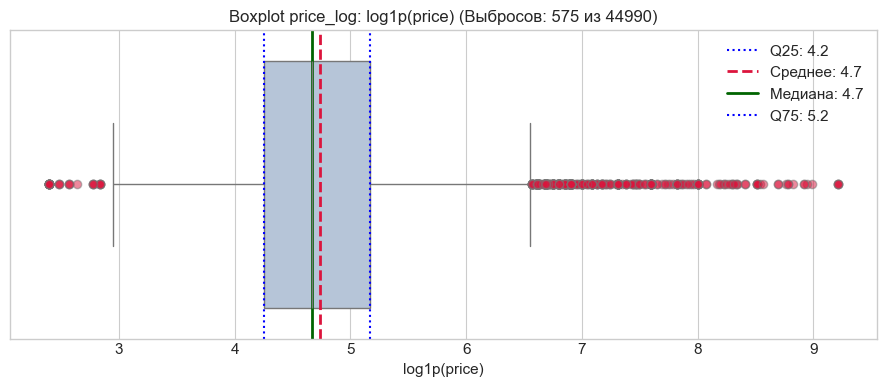

In [15]:
plot_boxplot_bounds(price_log, title="Boxplot price_log")

Признак 'price': удалено 2736 записей (6.1%). Осталось: от -90.0 до 334.0


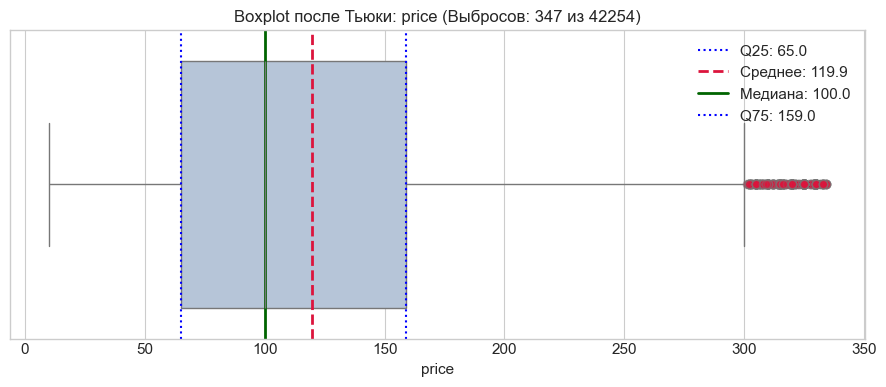

Признак 'price': удалено 1202 записей (2.7%). Осталось: от -193.84 до 498.35


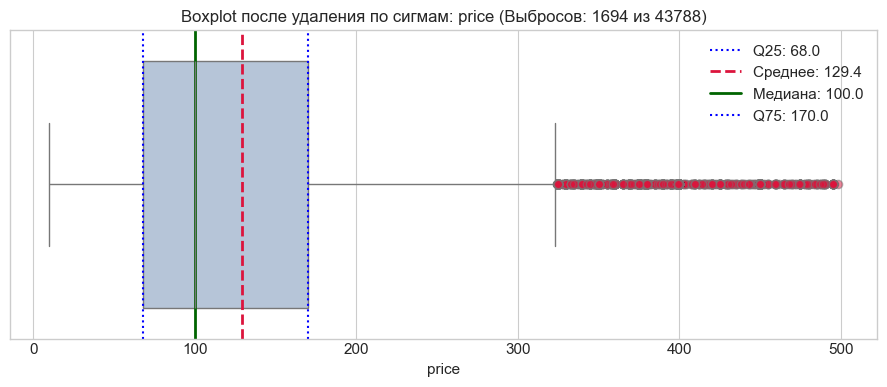

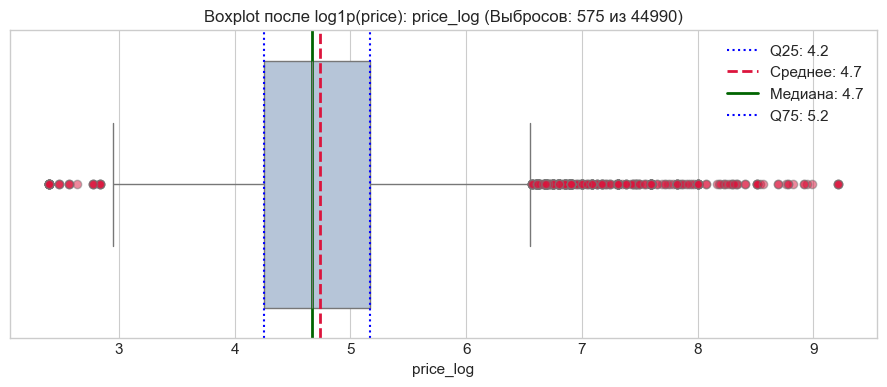

In [16]:
# СМОТРИМ PRICE ДО ЛОГАРИФМИРОВАНИЯ
# 1. Убираем физически некорректные цены price == 0
df_clean = df_global[df_global['price'] > 0].copy()

# 2. Фильтрация ценовых аномалий по правилу Тьюки
df_filtered_price = remove_outliers_quartiles(df_clean, 'price', factor=1.5)
plot_boxplot_bounds(df_filtered_price['price'], title="Boxplot после Тьюки")

# 3. Фильтрация ценовых аномалий по сигмам
df_filtered_price = remove_outliers_sigma(df_clean, 'price', factor=1.5)
plot_boxplot_bounds(df_filtered_price['price'], title="Boxplot после удаления по сигмам")

# 4. Альтернатива: логарифмирование и анализ boxplot трансформированной цены
df_clean['price_log'] = np.log1p(df_clean['price'])
plot_boxplot_bounds(df_clean['price_log'], title="Boxplot после log1p(price)")

Удаление после логарифмирования:
Признак 'price_log': удалено 575 записей (1.3%). Осталось: от 2.8655121125661713 до 6.553467124521339


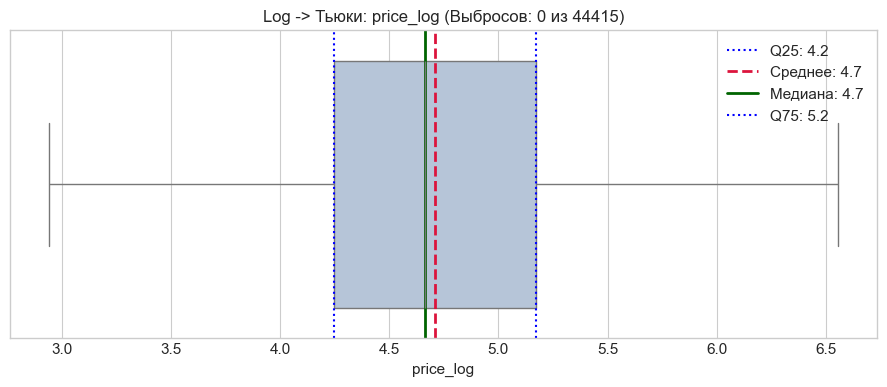

Удаление до логарифмирования:
Признак 'price': удалено 2736 записей (6.1%). Осталось: от -90.0 до 334.0
Крайние значения: Осталось: от 2.3978952727983707 до 5.814130531825066


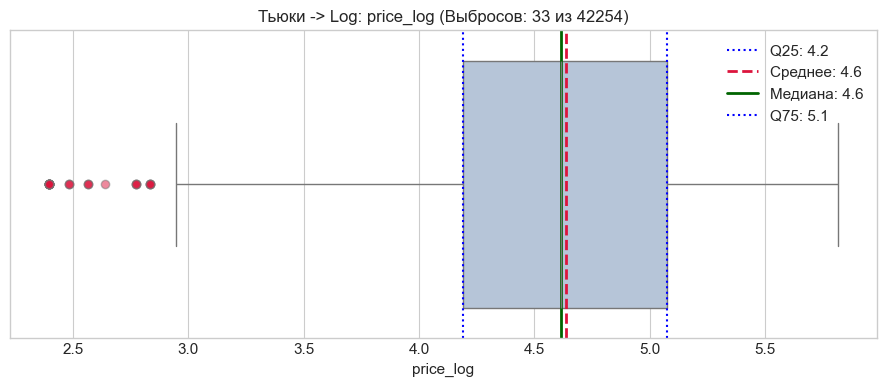

In [17]:
# А теперь сравним разницу между лог + удаление и наоборот
# 2. Фильтрация ценовых аномалий по правилу Тьюки

df_log_del = df_clean.copy()
# применяем именно тьюки, потому что у нас даже с логарифмом не нормальное распределение
print("Удаление после логарифмирования:")
df_log_del = remove_outliers_quartiles(df_log_del, 'price_log', factor=1.5)
plot_boxplot_bounds(df_log_del['price_log'], title="Log -> Тьюки")

df_del_log = df_clean.drop(columns=["price_log"]).copy()
print("Удаление до логарифмирования:")
df_del_log = remove_outliers_quartiles(df_del_log, 'price', factor=1.5)
df_del_log['price_log'] = np.log1p(df_del_log['price'])
print(f"Крайние значения: Осталось: от {df_del_log['price_log'].min()} до {df_del_log['price_log'].max()}")
plot_boxplot_bounds(df_del_log['price_log'], title="Тьюки -> Log")

---
## 6. Пропущенные значения и концепция Data Leakage

### Природа пропусков:
* **Случайные**: пропуски возникают случайно, независимо от других колонок.
* **Структурные**: колонка `reviews_per_month` пуста не из-за сбоя базы данных, а потому что у жилья еще **нет ни одного отзыва** (`reviews_count == 0`). Слепое заполнение средней или медианой припишет новому жилью активность старых квартир! Единственно верная стратегия здесь — заполнение нулем (`fillna(0)`).

In [18]:
print("Количество пропущенных значений по столбцам:")
missing = df_clean.isna().sum()
print(missing[missing > 0])

# проверим, связаны ли последние два
print("Связаны? ", df_clean["last_review_date"].isna().equals(df_clean["reviews_per_month"].isna()))

# Структурный пропуск reviews_per_month заполняем 0 (нет отзывов)
# на host_name пока что наплевать, он ничего не даёт
df_clean['last_review_date'] = df_clean['last_review_date'].fillna("1970-01-01")
df_clean['reviews_per_month'] = df_clean['reviews_per_month'].fillna(0.0)

Количество пропущенных значений по столбцам:
host_name              20
last_review_date     9262
reviews_per_month    9262
dtype: int64
Связаны?  True


In [19]:
model = train_test_linear_regression(df_clean, numeric_cols, 'price')
# --- Результаты ---
# R² на обучающей выборке (train): 0.145
# R² на тесте (test): 0.1318

--- Результаты ---
R² на обучающей выборке (train): 0.046
R² на тесте (test): 0.0289


### Концепция утечки данных (Data Leakage):
> **Главное правило предобработки в ML:**  
> Тестовая выборка (`test`) имитирует будущее, к которому у нас нет доступа во время обучения модели.  
> **Вычисление любых агрегированных параметров (среднее, медиана, квантили, скейлеры) ДО разделения на `train` и `test` является критической ошибкой (Data Leakage)!**

Если рассчитать среднее по всей таблице, информация из теста просочится в обучающий набор. Проверка покажет обманчиво высокую точность, а при развертывании в боевой среде модель потерпит крах.

In [20]:
feature_columns = ['latitude', 'longitude', 'min_nights', 'reviews_count', 
                   'reviews_per_month', 'host_listings_count', 'availability_365']

model = train_test_linear_regression(df_clean, feature_columns, "price_log")

--- Результаты ---
R² на обучающей выборке (train): 0.145
R² на тесте (test): 0.1318


In [21]:
leaked_price = 'price'
feature_columns_leaked = feature_columns + [leaked_price]

model = train_test_linear_regression(df_clean, feature_columns_leaked, "price_log")

leaked_X = df_clean[feature_columns_leaked]
leaked_y = df_clean['price_log']

leaked_X_train, leaked_X_test, _, leaked_y_test = train_test_split(
    leaked_X, leaked_y, test_size=0.3, random_state=RANDOM_STATE
)

# на новых данных у нас не будет price
if leaked_price in leaked_X_test.columns:
    leaked_X_test.drop(columns=[leaked_price], inplace=True)
    
try:
    leaked_pred = model.predict(leaked_X_test)
except ValueError as e:
    print("\nМодель упала с ошибкой!")
    print(f"Текст ошибки из библиотеки:\n{e}")
    
# попробуем заполнить отсутствующую колонку нулями, чтобы модель не падала
price_median = leaked_X_train[leaked_price].median()
leaked_X_test[leaked_price] = price_median

leaked_pred = model.predict(leaked_X_test)
leaked_r2 = r2_score(y_pred=leaked_pred, y_true=leaked_y_test)
print(f"R² на новых данных c price=median (test): {leaked_r2:.4f}")


--- Результаты ---
R² на обучающей выборке (train): 0.512
R² на тесте (test): 0.4506

Модель упала с ошибкой!
Текст ошибки из библиотеки:
The feature names should match those that were passed during fit.
Feature names seen at fit time, yet now missing:
- price

R² на новых данных c price=median (test): 0.1079


---
## 7. Сквозной интерактивный разбор и формулирование гипотез

### Обобщим всё, что мы надумали за лекцию

* listing_id, host_id: удалить (по host_id можно посчитать групповые статистики)
* name, host_name: host_name удалить; 
* из name извлечь флаги (КАПС, эмодзи)
* price (Таргет): отфильтровать $0, сжать правый хвост через log1p(x)
* min_nights: отрезать аномалии, логарифмировать? Что лучше? Почему? 
* reviews_per_month: стоит ли масштабировать? Почему?
* host_listings_count: что можно с ним придумать? может, попробовать как-то по количеству объявлений понять, кто хост?
* availability_365: проверьте, все ли значения адекватные? в [0; 365]?
* **может**, какие-то признаки не стоит использовать в чистом виде? или вообще не стоит использовать...

* после преобразований проверить качество модели, нет ли утечки?)

### Можете придумывать новые признаки, но ГЛАВНЫЕ задачи - описание действий:
* ЧТО вы делаете, 
* ПОЧЕМУ вы это делаете, 
* ЧТО ожидаете получить от своего действия 


In [22]:
your_columns = [
    "latitude",
    "longitude",
    "min_nights",
    "reviews_count",
    "reviews_per_month",
    "host_listings_count",
    "availability_365",
]
target = "price_log"
# dataframe - исходные данные (типа pd.DataFrame), 
# feature_columns - имена фичей, на которых вы хотите обучить модель,
# target - имя целевой переменной
model = train_test_linear_regression(
    dataframe=df_clean, feature_columns=your_columns, target=target
)

--- Результаты ---
R² на обучающей выборке (train): 0.145
R² на тесте (test): 0.1318
